# 03 — Joint Energy-based Model

**Goal**: learn, within the same network, both the priority p(y | x) **and** the plausibility p(x) of a bug, to obtain an atypicality signal the classifier lacks.

**Key findings**

- A classifier's implicit energy is **inverted**: it is lowest far from the data, in 2D as on real bugs (bots detected with an AUROC of 0.27, worse than chance).
- Trained as a JEM, the same network recovers a sensible energy landscape (low on the data, high elsewhere) with no loss of accuracy.
- `alpha` (weight of the generative term) is chosen on the **2025 validation set**: `alpha = 1` gives the best detection of 2025 bot bugs (0.77) and a slightly better validation NLL than the classifier (1.127 vs 1.134).
- Cost: ~13× more time per epoch (20 Langevin steps per batch), and a detection score that fluctuates from one epoch to the next.

Reference: Grathwohl et al., *Your classifier is secretly an energy based model and you should treat it like one*, ICLR 2020.

In [1]:
import logging
import os
import warnings
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")  # paths are relative to the project root (data/, mlflow.db)

warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

from jem_prioriser.plotstyle import CLASS_COLORS, HUMAN_BOT_COLORS, MODEL_COLORS, SERIES, use_style

logging.getLogger("mlflow").setLevel(logging.ERROR)
use_style()
pd.set_option("display.max_colwidth", 90)

## 1. The energy hidden in a classifier

A classifier outputs logits f(x); the softmax only keeps their differences. Their overall level defines an energy:

$$E(x) = -\log \sum_y e^{f(x)_y}, \qquad p(x) \propto e^{-E(x)}, \qquad p(y \mid x) = \mathrm{softmax}(f(x))_y$$

This reading leaves p(y | x) unchanged, but nothing in the cross-entropy constrains E(x). Illustration on three 2D point clouds, using the same `MLP` and loss function as on bugs:

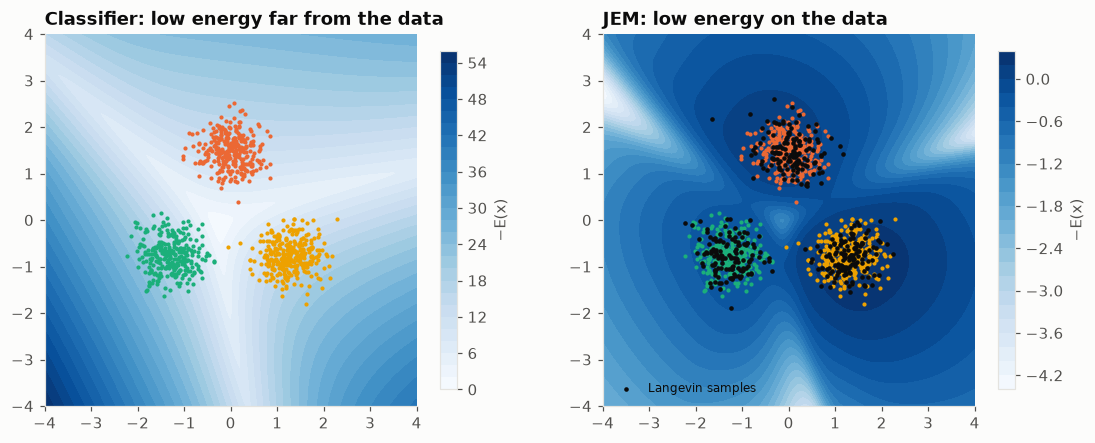

accuracy: classifier 1.000 | JEM 1.000


In [2]:
import torch
from jem_prioriser import toy
from jem_prioriser.model import sgld

x_toy, y_toy = toy.make_toy()
clf_toy, _ = toy.train_toy(x_toy, y_toy, alpha=0)
jem_toy, buf_toy = toy.train_toy(x_toy, y_toy, alpha=1)

def plot_landscape(ax, model, title, samples=None):
    xx, yy, e = toy.energy_grid(model)
    cs = ax.contourf(xx, yy, -e, levels=30, cmap="Blues")
    plt.colorbar(cs, ax=ax, shrink=0.8, label="−E(x)")
    for k in range(3):
        pts = x_toy[y_toy == k]
        ax.scatter(pts[:, 0], pts[:, 1], s=3, color=SERIES[1:4][k])
    if samples is not None:
        ax.scatter(samples[:, 0], samples[:, 1], s=4, color="#0b0b0b", label="Langevin samples")
        ax.legend(loc="lower left", fontsize=8)
    ax.set_title(title); ax.set_aspect("equal"); ax.grid(False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_landscape(axes[0], clf_toy, "Classifier: low energy far from the data")
plot_landscape(axes[1], jem_toy, "JEM: low energy on the data", buf_toy.buffer.numpy()[:400])
plt.show()
acc = lambda m: (m(torch.from_numpy(x_toy)).argmax(1).numpy() == y_toy).mean()
print(f"accuracy: classifier {acc(clf_toy):.3f} | JEM {acc(jem_toy):.3f}")

To separate the classes, the classifier makes its logits grow away from the decision boundaries, including beyond the data: far from everything, it is both very confident and very low-energy. The same holds on real bugs, with the MLP from notebook 02:

In [3]:
from jem_prioriser.metrics import ood_auroc
from jem_prioriser.train import EXPERIMENT, TRACKING_URI, predict, prepare_data

mlflow.set_tracking_uri(TRACKING_URI)
run = mlflow.search_runs(experiment_names=[EXPERIMENT], filter_string="tags.mlflow.runName = 'baseline-mlp'",
                         order_by=["start_time DESC"]).iloc[0]
baseline = mlflow.pyfunc.load_model(f"runs:/{run.run_id}/prioriser").unwrap_python_model().prioriser
data = prepare_data()
_, e_hum = predict(baseline.model, data.x_test)
_, e_bot = predict(baseline.model, data.x_bots)
print(f"mean energy: human bugs {e_hum.mean():.2f} | bot bugs {e_bot.mean():.2f}")
print(f"AUROC for detecting bots with the classifier's energy: {ood_auroc(e_hum, e_bot):.2f}")

mean energy: human bugs -1.64 | bot bugs -2.01
AUROC for detecting bots with the classifier's energy: 0.27


## 2. Method

**Joint loss.** An estimator of the gradient of $-\log p(x)$ is added to the cross-entropy:

$$\mathcal{L} = \mathrm{CE}(f(x), y) + \alpha\Big[\overline{E(x_{\text{data}})} - \overline{E(x_{\text{model}})} + \lambda\big(\overline{E(x_{\text{data}})^2} + \overline{E(x_{\text{model}})^2}\big)\Big]$$

The first bracketed term lowers the energy of real bugs, the second raises that of samples the model currently finds plausible; $\lambda = 0.1$ keeps energies from diverging.

**Sampling (SGLD).** The $x_{\text{model}}$ samples are drawn with Langevin dynamics, which only needs $\nabla_x E$ (the normalising constant vanishes when differentiating):

$$x_{t+1} = x_t - \eta\,\nabla_x E(x_t) + \sigma\,\varepsilon_t, \qquad \eta = 1,\ \sigma = 0.01,\ 20 \text{ steps}$$

**Replay buffer.** 10,000 persistent samples: each chain resumes where it stopped (*Persistent Contrastive Divergence*), and 5% are re-initialised with noise at each draw.

**Implementation details** (`jem_prioriser.model`, `jem_prioriser.train`): no BatchNorm or Dropout, SiLU activation (smooth input gradients), 2 cross-entropy-only warm-up epochs, epoch selection on validation NLL among epochs where the generative term is active.

Langevin chains of the 2D model, started from uniform noise:

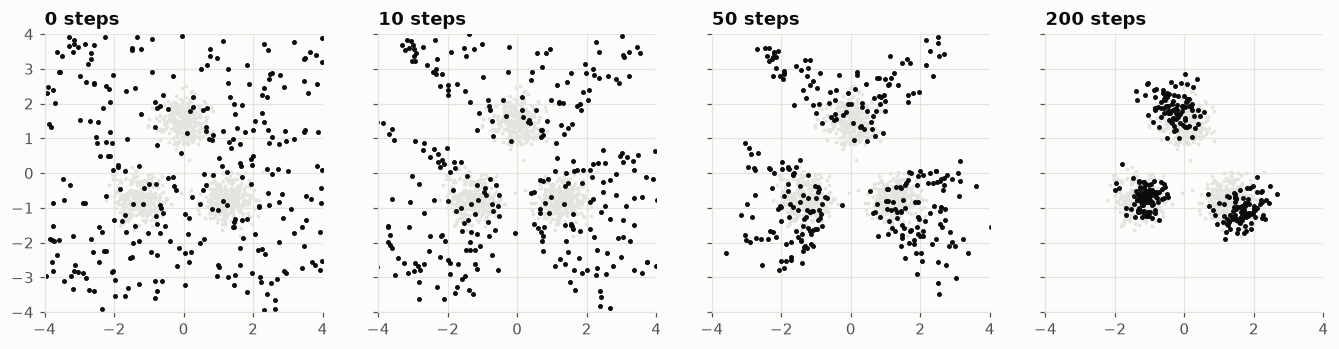

In [4]:
torch.manual_seed(1)
x_cur, done = torch.rand(300, 2) * 8 - 4, 0
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharex=True, sharey=True)
for ax, n_steps in zip(axes, [0, 10, 50, 200]):
    if n_steps > done:
        x_cur = sgld(jem_toy, x_cur, n_steps=n_steps - done, step_size=0.05, noise=0.05)
    done = n_steps
    ax.scatter(x_toy[:, 0], x_toy[:, 1], s=2, color="#e4e3df")
    ax.scatter(x_cur[:, 0].numpy(), x_cur[:, 1].numpy(), s=5, color="#0b0b0b")
    ax.set_title(f"{n_steps} steps"); ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal")
plt.show()

## 3. Selecting `alpha` on the validation set

Criteria measured on 2025 only: validation NLL at the retained epoch, and AUROC for detecting **bot bugs filed in 2025** by energy. 2026 bugs and bot bugs are reserved for the test (`train.bots_of_period`). These runs are logged to MLflow without serialising the model.

In [5]:
from jem_prioriser.train import TrainConfig, train

def selected_epoch(history, cfg):
    rows = [r for r in history if cfg.alpha == 0 or r["epoch"] > cfg.warmup_epochs]
    return min(rows, key=lambda r: r["val_nll"])

sweep = []
for alpha in [0.0, 0.1, 0.3, 1.0, 3.0]:
    cfg = TrainConfig(alpha=alpha)
    res = train(cfg, data, run_name=f"sweep-alpha{alpha}", log_model=False, verbose=False)
    best = selected_epoch(res.history, cfg)
    sweep.append({"alpha": alpha, "epoch": best["epoch"], "val_nll": best["val_nll"], "val_accuracy": best["val_accuracy"],
                  "val_ece": best["val_ece"], "val_ood_auroc": best["val_ood_auroc_energy"],
                  "s/epoch": np.mean([r["seconds"] for r in res.history])})
sweep = pd.DataFrame(sweep)
sweep.round(3)

,alpha,epoch,val_nll,val_accuracy,val_ece,val_ood_auroc,s/epoch
0,0.0,2,1.134,0.525,0.022,0.246,0.335
1,0.1,3,1.129,0.516,0.028,0.581,4.324
2,0.3,4,1.129,0.525,0.029,0.669,4.245
3,1.0,5,1.127,0.529,0.021,0.771,4.592
4,3.0,6,1.140,0.510,0.031,0.683,4.657


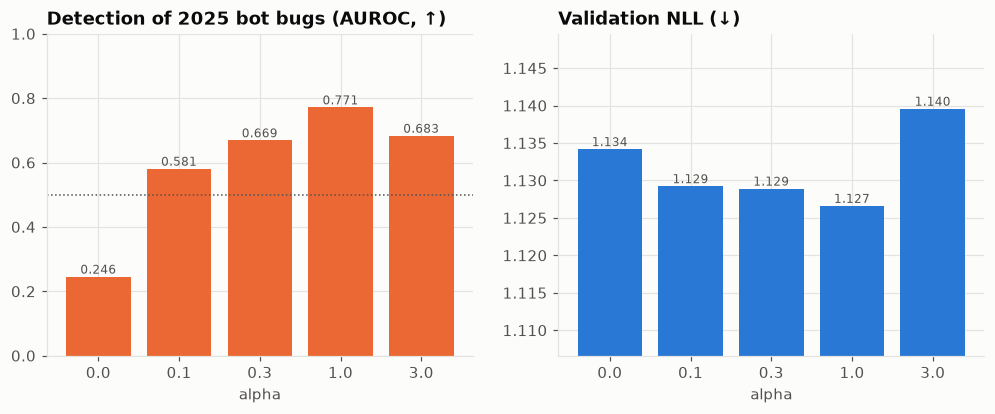

selected alpha: 1.0


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
labels = [str(a) for a in sweep.alpha]
axes[0].bar(labels, sweep.val_ood_auroc, color=SERIES[1])
axes[0].axhline(0.5, color="#52514e", linestyle=":", linewidth=1)
axes[0].set_title("Detection of 2025 bot bugs (AUROC, ↑)"); axes[0].set_xlabel("alpha"); axes[0].set_ylim(0, 1)
axes[1].bar(labels, sweep.val_nll, color=SERIES[0])
axes[1].set_ylim(sweep.val_nll.min() - 0.02, sweep.val_nll.max() + 0.01)
axes[1].set_title("Validation NLL (↓)"); axes[1].set_xlabel("alpha")
for ax, col in [(axes[0], "val_ood_auroc"), (axes[1], "val_nll")]:
    for i, v in enumerate(sweep[col]):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8, color="#52514e")
plt.show()

# Rule fixed before evaluation: best detection without degrading the NLL by more than 0.01
base_nll = sweep.loc[sweep.alpha == 0, "val_nll"].item()
ok = sweep[(sweep.alpha > 0) & (sweep.val_nll <= base_nll + 0.01)]
best_alpha = float(ok.loc[ok.val_ood_auroc.idxmax(), "alpha"])
print(f"selected alpha: {best_alpha}")

- Detection improves with `alpha` up to 1; beyond that the generative term takes over from classification (`alpha = 3`: worse NLL).
- At `alpha = 1`, the validation NLL is **better** than the classifier's and the best epoch comes later (5 instead of 2): the generative term acts as a regulariser that curbs logit growth.
- Cost: ~4.5 s per epoch vs 0.35 s, i.e. ~13× more.

## 4. Final training

In [7]:
jem = train(TrainConfig(alpha=best_alpha), data, run_name="jem")

[ 1/20] ce=1.159 | val acc=0.511 f1=0.445 nll=1.141 ece=0.020 ood=0.28 (0.4s)


[ 2/20] ce=1.027 | val acc=0.523 f1=0.473 nll=1.135 ece=0.019 ood=0.26 (0.3s)


[ 3/20] ce=1.117 gen=+0.505 | val acc=0.502 f1=0.372 nll=1.153 ece=0.036 ood=0.67 (4.7s)


[ 4/20] ce=1.021 gen=+0.068 | val acc=0.519 f1=0.445 nll=1.128 ece=0.031 ood=0.72 (4.6s)


[ 5/20] ce=0.994 gen=+0.005 | val acc=0.528 f1=0.463 nll=1.127 ece=0.021 ood=0.77 (4.6s)


...

[16/20] ce=0.897 gen=-0.066 | val acc=0.515 f1=0.454 nll=1.166 ece=0.045 ood=0.57 (4.7s)


[17/20] ce=0.884 gen=-0.082 | val acc=0.526 f1=0.463 nll=1.164 ece=0.039 ood=0.58 (4.5s)


[18/20] ce=0.870 gen=-0.080 | val acc=0.526 f1=0.468 nll=1.163 ece=0.039 ood=0.76 (4.5s)


[19/20] ce=0.855 gen=-0.094 | val acc=0.527 f1=0.468 nll=1.176 ece=0.038 ood=0.62 (4.5s)


[20/20] ce=0.838 gen=-0.104 | val acc=0.529 f1=0.466 nll=1.180 ece=0.039 ood=0.68 (4.6s)


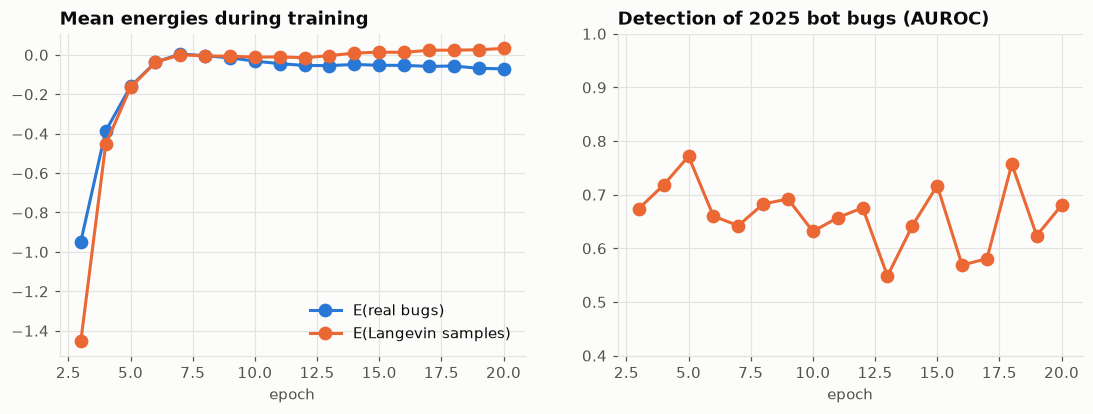

In [8]:
h = pd.DataFrame(jem.history)
h = h[h.epoch > TrainConfig().warmup_epochs]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(h.epoch, h.train_e_pos, marker="o", label="E(real bugs)")
axes[0].plot(h.epoch, h.train_e_neg, marker="o", label="E(Langevin samples)")
axes[0].set_title("Mean energies during training"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(h.epoch, h.val_ood_auroc_energy, marker="o", color=SERIES[1])
axes[1].set_title("Detection of 2025 bot bugs (AUROC)"); axes[1].set_xlabel("epoch"); axes[1].set_ylim(0.4, 1)
plt.show()

- Data and sample energies stay close and bounded: training is stable, with no divergence.
- Detection appears from the first generative epoch (0.67) but then **fluctuates** between 0.55 and 0.77: Langevin sampling is noisy and the energy landscape shifts at every iteration. Its variability across seeds is measured in notebook 04.